# A/B-тест: анализ конверсии в заказ

**Портфолио · Product / Data Analytics**  
**Инструменты:** Python, pandas, scipy, statsmodels, matplotlib

## Бизнес-задача

Сравнить конверсию в заказ (`nflag_order`) между контрольной группой **A (`id_group = 0`)** и тестовой группой **B (`id_group = 1`)**, оценить неопределённость эффекта и понять, насколько устойчиво направление результата в разных городах и временных интервалах.

**H₀:** конверсии A и B равны.  
**H₁:** конверсии различаются (двусторонний тест, α = 0,05).

> ⚠️ Публичный режим работает на **полностью синтетическом демо-наборе**. Он нужен только для проверки кода. Чтобы воспроизвести учебное исследование, переключите `DATA_MODE` на `original` и положите исходный Excel локально в `data/private/`. Результаты демо **не являются** результатами исходного эксперимента.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Поддерживаем запуск из корня репозитория и из notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.analysis import (prepare_events, group_table, experiment_result,
                          sample_ratio_mismatch, by_city, by_peak_hour)

DATA_MODE = 'demo'  # 'demo' — открытые синтетические данные; 'original' — локальный исходный Excel
SOURCE_FILE = ROOT / 'data' / 'private' / 'Финальная первичная аттестация. Вариант 1. Python.xlsx'

## 1. Загрузка данных

Набор исходных полей: `id_view` (идентификатор просмотра), `time_view` (время события), `id_group` (0/1), `id_city`, `nflag_order` (0/1). Справочник связывает `id_city` и `name_city`.

**Важно:** отдельного `user_id` в учебных данных нет; нельзя проверить число событий на пользователя и независимость наблюдений.

In [2]:
if DATA_MODE == 'demo':
    events = pd.read_csv(ROOT / 'data' / 'demo' / 'events.csv')
    cities = pd.read_csv(ROOT / 'data' / 'demo' / 'cities.csv')
else:
    if not SOURCE_FILE.exists():
        raise FileNotFoundError('Исходный Excel не найден в data/private/. Файл не входит в публичный репозиторий.')
    events = pd.read_excel(SOURCE_FILE, sheet_name='Dataset')
    cities = pd.read_excel(SOURCE_FILE, sheet_name='city_dict')
    # В некоторых версиях Excel время возвращается числом (серийная дата Excel).
    if pd.api.types.is_numeric_dtype(events['time_view']):
        events['time_view'] = pd.to_datetime(events['time_view'], unit='D', origin='1899-12-30')

df = prepare_events(events, cities)
print('Режим:', DATA_MODE, '| Наблюдений:', len(df), '| Городов:', df['name_city'].nunique())
print('Период:', df['time_view'].min(), '—', df['time_view'].max())
df.head()

Режим: demo | Наблюдений: 8000 | Городов: 11
Период: 2023-01-01 00:02:42.879668966 — 2023-01-31 23:58:35.052029121
Out[2]: 
    id_view                     time_view  ...  nflag_order        name_city
0  20000001 2023-01-23 10:00:28.476233754  ...            0  Санкт-Петербург
1  20000002 2023-01-07 10:59:11.207015594  ...            0           Москва
2  20000003 2023-01-21 16:01:00.250859202  ...            1           Москва
3  20000004 2023-01-31 15:18:11.456044978  ...            0        Краснодар
4  20000005 2023-01-08 18:59:36.270575450  ...            1           Москва

[5 rows x 6 columns]


,id_view,time_view,id_group,id_city,nflag_order,name_city
0,20000001,2023-01-23 10:00:28.476233754,0,2,0,Санкт-Петербург
1,20000002,2023-01-07 10:59:11.207015594,1,1,0,Москва
2,20000003,2023-01-21 16:01:00.250859202,0,1,1,Москва
3,20000004,2023-01-31 15:18:11.456044978,1,5,0,Краснодар
4,20000005,2023-01-08 18:59:36.270575450,1,1,1,Москва


## 2. Контроль качества данных

Проверяем пропуски, дубликаты ключа, значения конверсии и групп, совпадения по справочнику городов. `prepare_events` останавливает выполнение при нарушениях.

In [3]:
print('Пропуски по ключевым полям:')
print(df[['id_view','time_view','id_group','id_city','nflag_order']].isna().sum().to_string())
print('Дублирующиеся id_view:', df['id_view'].duplicated().sum())
print('Распределение по группам:')
print(df['id_group'].value_counts().sort_index().to_string())

Пропуски по ключевым полям:
id_view        0
time_view      0
id_group       0
id_city        0
nflag_order    0
Дублирующиеся id_view: 0
Распределение по группам:
id_group
0    4025
1    3975


## 3. Проверка распределения A/B (SRM)

Тестируем **предположительное** плановое соотношение 50/50. Это лишь диагностика sample ratio mismatch, а не доказательство корректной рандомизации. Если плановая пропорция была иной — её необходимо заменить.

In [4]:
srm = sample_ratio_mismatch(df, expected_control_share=0.5)
print('Группа A:', srm['control_n'], '| группа B:', srm['test_n'])
print(f"χ² = {srm['chi2']:.3f}; p-value = {srm['p_value']:.5f}")
print('SRM-флаг на α=0.05:', 'есть' if srm['p_value'] < 0.05 else 'не обнаружен')

Группа A: 4025 | группа B: 3975
χ² = 0.312; p-value = 0.57615
SRM-флаг на α=0.05: не обнаружен


## 4. Основное сравнение конверсий

Для бинарного показателя используем двусторонний **z-тест двух долей**. Для абсолютного эффекта B–A считаем 95% доверительный интервал по методу **Ньюкомба**. Обе процедуры предполагают независимость единиц наблюдения; по отсутствующему `user_id` это невозможно проверить.

In [5]:
overall = experiment_result(df)
print(f"A: {overall['a_orders']}/{overall['a_n']} = {overall['a_conversion']:.2%}")
print(f"B: {overall['b_orders']}/{overall['b_n']} = {overall['b_conversion']:.2%}")
print(f"Разница B–A: {overall['effect_pp']:+.2f} п.п.; относительный эффект: {overall['relative_effect_pct']:+.2f}%")
print(f"95% ДИ: [{overall['ci_low_pp']:+.2f}; {overall['ci_high_pp']:+.2f}] п.п.")
print(f"z = {overall['z']:.3f}; p = {overall['p_value']:.3g}")

A: 2445/4025 = 60.75%
B: 2564/3975 = 64.50%
Разница B–A: +3.76 п.п.; относительный эффект: +6.19%
95% ДИ: [+1.64; +5.87] п.п.
z = 3.473; p = 0.000514


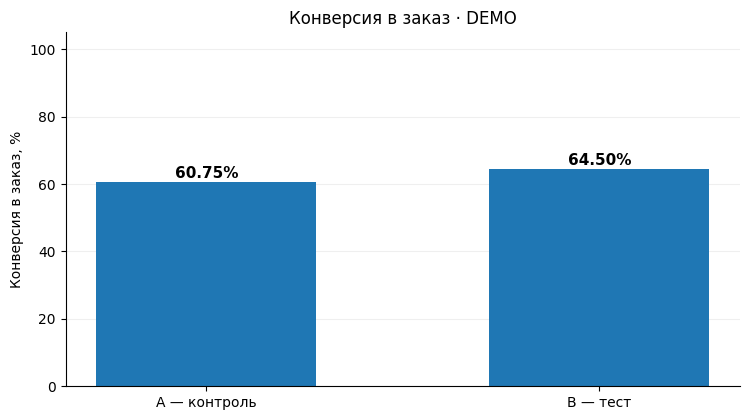

In [6]:
rates = group_table(df)
fig, ax = plt.subplots(figsize=(7.6, 4.3))
ax.bar(['A — контроль', 'B — тест'], rates['conversion'] * 100, width=.56)
for i, r in enumerate(rates['conversion']):
    ax.text(i, r * 100 + 1, f'{r:.2%}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 105)
ax.set_ylabel('Конверсия в заказ, %')
ax.set_title(f'Конверсия в заказ · {DATA_MODE.upper()}')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 5. Разрез по городам

Для исследовательских сравнений по городам применяется поправка **Холма**. На графике показаны индивидуальные 95% ДИ без поправки на множественность. Наличие значимого результата в одном городе и незначимого в другом **не доказывает** разницу эффектов между городами: для этого нужно отдельно проверить взаимодействие `группа × город`.

Разрез по городам — **исследовательский**, если не был заранее объявлен в плане эксперимента.

In [7]:
cities_result = by_city(df)
columns = ['city','a_n','b_n','a_conversion','b_conversion','effect_pp','ci_low_pp','ci_high_pp','p_value','p_holm','significant_holm']
print(cities_result[columns].round(4).to_string(index=False))

           city  a_n  b_n  a_conversion  b_conversion  effect_pp  ci_low_pp  ci_high_pp  p_value  p_holm  significant_holm
         Москва 1617 1612        0.6067        0.6588     5.2130     1.8877      8.5219   0.0021  0.0234              True
Санкт-Петербург  887  949        0.6020        0.6333     3.1269    -1.3172      7.5606   0.1682  1.0000             False
    Новосибирск  595  540        0.6454        0.6352    -1.0193    -6.5999      4.5509   0.7208  1.0000             False
         Казань  228  231        0.6009        0.6147     1.3841    -7.4947     10.2372   0.7614  1.0000             False
      Краснодар  149  143        0.5436        0.6294     8.5746    -2.7033     19.5323   0.1370  1.0000             False
      Челябинск  142  134        0.5563        0.7313    17.5005     6.1943     28.1524   0.0024  0.0245              True
           Сочи  114  105        0.6316        0.6667     3.5088    -9.0732     15.8531   0.5869  1.0000             False
        Воронеж 

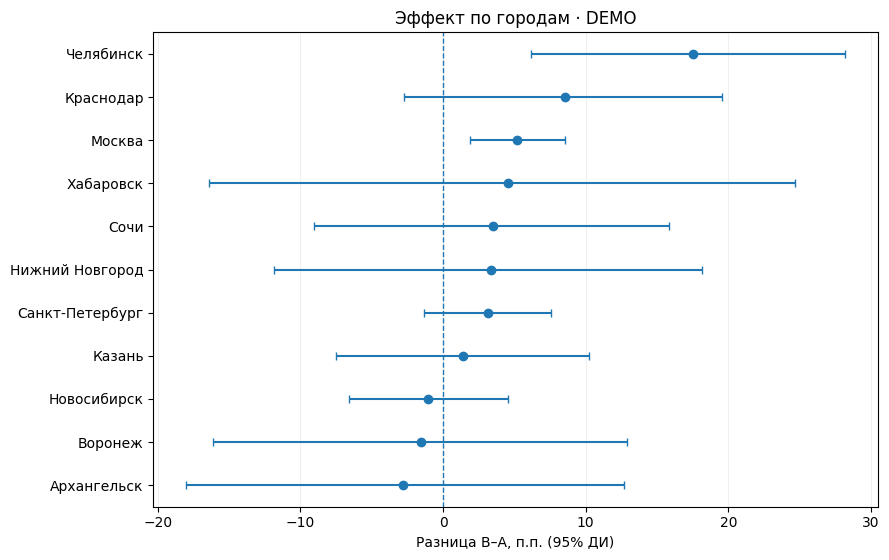

In [8]:
ordered = cities_result.sort_values('effect_pp')
fig, ax = plt.subplots(figsize=(9, 5.7))
ax.errorbar(ordered['effect_pp'], ordered['city'],
            xerr=[ordered['effect_pp']-ordered['ci_low_pp'], ordered['ci_high_pp']-ordered['effect_pp']],
            fmt='o', capsize=3)
ax.axvline(0, linestyle='--', linewidth=1)
ax.set_xlabel('Разница B–A, п.п. (95% ДИ)')
ax.set_title(f'Эффект по городам · {DATA_MODE.upper()}')
ax.grid(axis='x', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 6. Пиковые и непиковые часы

В исходном учебном задании «пиковыми» названы часы **07:00–10:59 и 17:00–20:59**. Ниже показаны эффекты отдельно для двух периодов. Даже если оба сегментных теста значимы, это не доказывает, что эффект отличается между периодами.

In [9]:
time_result = by_peak_hour(df)
print(time_result[['period','a_n','b_n','a_conversion','b_conversion','effect_pp','ci_low_pp','ci_high_pp','p_value']].round(4).to_string(index=False))

        period  a_n  b_n  a_conversion  b_conversion  effect_pp  ci_low_pp  ci_high_pp  p_value
Непиковые часы 2622 2598        0.6034        0.6520     4.8684     2.2458      7.4812   0.0003
  Пиковые часы 1403 1377        0.6151        0.6318     1.6698    -1.9313      5.2634   0.3636


## 7. Бизнес-интерпретация и ограничения

**Что видно в данных:** оценка разницы конверсий и её доверительный интервал позволяют понять направление и точность эффекта в анализируемой выборке. Географические и временные разрезы помогают предложить следующие проверки, но не заменяют основной эксперимент.

**Что нельзя утверждать из этой таблицы:**

1. Что именно поменяли в варианте B: описание изменения отсутствует.
2. Что группы рандомизировали по *пользователю* и строки независимы: есть `id_view`, но нет `user_id`.
3. Что улучшился доход, маржинальность или долгосрочное удержание: здесь нет денежных или retention-метрик.
4. Что эффект особенно сильный в конкретном городе: без отдельного теста взаимодействия такая интерпретация не доказана.
5. Что experiment rollout безопасен: отсутствуют guardrail-метрики, дизайн эксперимента и период наблюдения после изменений.

**Рекомендация продуктовой команде:** предварительно интерпретировать результат как положительный сигнал для B, но решение о масштабировании принимать только после подтверждения рандомизации и единицы наблюдения, проверки качества логирования и оценки бизнес- и защитных метрик.

> Для исходного учебного Excel подтверждённые сводные результаты (отдельно от демо) приведены в `docs/original_results_summary.md`. Публичный синтетический набор создан независимо и не является анонимизированной копией учебных строк.